# 04 · SHAC-T method diagnostics

What the hierarchy looks like across the α grid and the ablations, from the variant runs that `scripts/sweep.py` builds through the evaluator's `build_cmd` (directories listed in `out/selection.json`). The questions:
1. Does the size cap prevent a giant cluster (ρ = 2 vs ρ = ∞)?
2. How much do super-nodes rebuild single papers (assumption A1), and how does α trade paper purity for type purity?
3. How much of the coarse hypergraph is genuinely multi-way, and how much λ−1 cut does each level remove?

Coherence, stability, labels and the extrinsic task are in `out/metrics.json` (`make metrics`) and the report tables.

In [1]:
from pathlib import Path
import json, os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from tkh.config import load_config
from tkh.io import load, snapshot
from tkh.coarsen import concept_nodes, hubs, incidence, collapse, connectivity_cut
from tkh.evalkit.artefacts import Run
from tkh.evaluate.stability import ari, labels

cfg = load_config(os.environ.get("TKH_CONFIG"))
tkh = load(cfg)
OUT = Path(cfg.out_dir)
sel = json.loads((OUT / "selection.json").read_text())
names = {cid: f"α={g['params']['alpha']:g}" for cid, g in sel["configs"].items()}
names.update({a["cid"]: k for k, a in sel["ablations"].items()})
dirs = {cid: g["dir"] for cid, g in sel["configs"].items()}
dirs.update({a["cid"]: a["dir"] for a in sel["ablations"].values()})
parts = {cid: Run(dirs[cid], cfg.cutoffs, tkh).concept_parts() for cid in names}
print("selected:", sel["winner"], "| configurations:", len(parts))

selected: a0.5_g0.5_r2_native_d100_h0.2 | configurations: 9


## 1 · Cluster sizes and the size cap

In [2]:
C = max(cfg.cutoffs)
rows = []
for cid, p in parts.items():
    for k, lv in enumerate(p[C]):
        s = np.array(sorted((len(m) for m in lv.values()), reverse=True))
        rows.append({"config": names[cid], "level": k, "n": len(s), "giant_share": s[0] / s.sum(),
                     "median_size": np.median(s), "singletons": int((s == 1).sum())})
sizes = pd.DataFrame(rows)
sizes.pivot(index="config", columns="level", values="giant_share").round(3)

level,0,1,2
config,,,
freeze,0.219,0.114,0.109
gamma0,0.133,0.033,0.008
projection,0.133,0.033,0.008
rho_inf,0.929,0.722,0.163
α=0,0.128,0.032,0.008
α=0.25,0.121,0.033,0.008
α=0.5,0.126,0.033,0.008
α=0.75,0.131,0.033,0.008
α=1,0.127,0.032,0.008


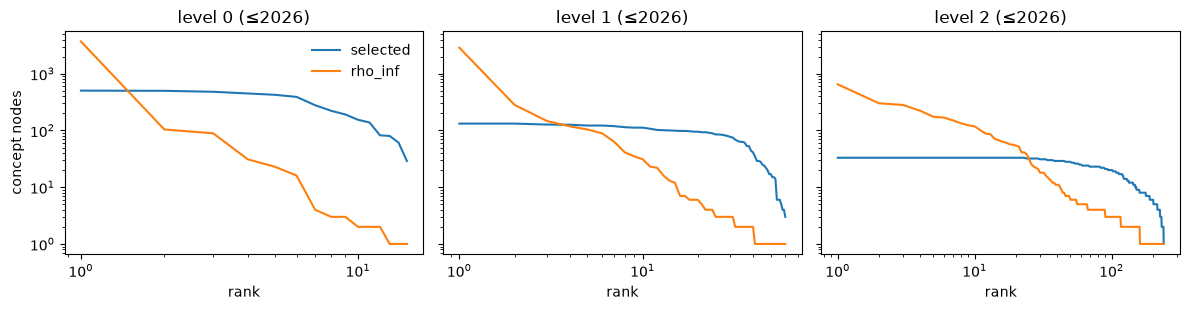

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for k, ax in enumerate(axes):
    for cid in [sel["winner"], sel["ablations"]["rho_inf"]["cid"]]:
        s = np.sort([len(m) for m in parts[cid][C][k].values()])[::-1]
        ax.plot(np.arange(1, len(s) + 1), s, label=names[cid] if cid != sel["winner"] else "selected")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"level {k} (≤{C})"); ax.set_xlabel("rank")
axes[0].set_ylabel("concept nodes"); axes[0].legend(frameon=False)
fig.tight_layout()

## 2 · Papers, types and α

Paper purity is the size-weighted share of a super-node's concept nodes whose earliest paper is the super-node's most common one. Type purity is the same for node types. ARI vs paper compares the level with the partition of concept nodes by earliest paper.

In [4]:
from tkh.coarsen import node_papers
snap = snapshot(tkh, C)
npap = node_papers(tkh, snap)
year = tkh.articles["year"].to_dict()
first_paper = {v: min(ps, key=lambda a: (year[a], str(a))) for v, ps in npap.items() if ps}
ntype = tkh.nodes["type"].to_dict()

def purity(lv, key):
    tot = hit = 0
    for m in lv.values():
        vals = pd.Series([key[v] for v in m if v in key])
        if len(vals):
            hit += vals.value_counts().iloc[0]; tot += len(vals)
    return hit / tot

rows = []
for cid, p in parts.items():
    for k, lv in enumerate(p[C]):
        nodes = sorted(v for m in lv.values() for v in m if v in first_paper)
        rows.append({"config": names[cid], "level": k, "paper_purity": purity(lv, first_paper),
                     "type_purity": purity(lv, ntype),
                     "ari_vs_paper": ari(labels(lv, nodes), [first_paper[v] for v in nodes])})
diag = pd.DataFrame(rows)
diag.pivot(index="config", columns="level", values=["paper_purity", "type_purity", "ari_vs_paper"]).round(3)

paper_purity               type_purity               ari_vs_paper  \
level                 0      1      2           0      1      2            0   
config                                                                         
freeze            0.221  0.407  0.602       0.332  0.469  0.570        0.112   
gamma0            0.198  0.442  0.705       0.482  0.621  0.819        0.102   
projection        0.180  0.338  0.656       0.425  0.600  0.802        0.070   
rho_inf           0.072  0.192  0.529       0.306  0.338  0.506        0.000   
α=0               0.216  0.523  0.838       0.404  0.658  0.896        0.137   
α=0.25            0.195  0.361  0.686       0.373  0.578  0.797        0.088   
α=0.5             0.178  0.354  0.662       0.379  0.580  0.807        0.072   
α=0.75            0.141  0.263  0.506       0.390  0.522  0.695        0.043   
α=1               0.091  0.167  0.282       0.362  0.426  0.515        0.014   

                          
level           1      2  
config                    
freeze      0.227  0.282  
gamma0      0.226  0.197  
projection  0.147  0.164  
rho_inf     0.018  0.231  
α=0         0.312  0.261  
α=0.25      0.166  0.173  
α=0.5       0.157  0.165  
α=0.75      0.087  0.104  
α=1         0.030  0.031

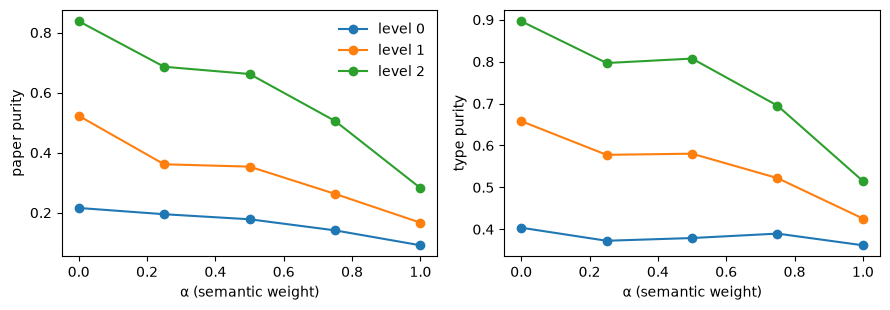

In [5]:
grid = diag[diag.config.str.startswith("α=")].assign(alpha=lambda d: d.config.str[2:].astype(float))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
for k in sorted(grid.level.unique()):
    g = grid[grid.level == k].sort_values("alpha")
    axes[0].plot(g.alpha, g.paper_purity, marker="o", label=f"level {k}")
    axes[1].plot(g.alpha, g.type_purity, marker="o")
axes[0].set_ylabel("paper purity"); axes[1].set_ylabel("type purity")
for ax in axes: ax.set_xlabel("α (semantic weight)")
axes[0].legend(frameon=False); fig.tight_layout()

## 3 · The coarse hypergraph: multi-way edges and the λ−1 cut

For every level, the fine clustering edges are collapsed onto the super-nodes (T4). An edge is *multi-way* if it still spans three or more super-nodes. A clique projection would split such edges into pairs. The λ−1 cut remaining is shown relative to the singleton partition.

In [6]:
items = concept_nodes(tkh, snap)
B, w, eids, rels = incidence(tkh, snap, items, hubs(tkh, snap, 0.2))
cut0 = connectivity_cut(np.asarray(B.sum(axis=0)).ravel(), w)
rows = []
for cid, p in parts.items():
    for k, lv in enumerate(p[C]):
        where = {v: i for i, m in enumerate(lv.values()) for v in m}
        coll = collapse(np.array([where[v] for v in items]), B)
        live = coll["cls"] != "internal"
        rows.append({"config": names[cid], "level": k, "internal": (~live).mean(),
                     "multiway_share_of_coarse": coll["multiway"][live].mean() if live.any() else 0.0,
                     "cut_remaining": connectivity_cut(coll["lam"], w) / cut0})
coarse = pd.DataFrame(rows)
coarse.pivot(index="config", columns="level", values=["internal", "multiway_share_of_coarse", "cut_remaining"]).round(3)

internal               multiway_share_of_coarse                \
level             0      1      2                        0      1      2   
config                                                                     
freeze        0.520  0.363  0.323                    0.248  0.272  0.448   
gamma0        0.397  0.184  0.065                    0.237  0.279  0.402   
projection    0.273  0.139  0.060                    0.313  0.346  0.470   
rho_inf       0.908  0.762  0.330                    0.294  0.311  0.407   
α=0           0.744  0.681  0.448                    0.352  0.401  0.343   
α=0.25        0.323  0.164  0.072                    0.243  0.335  0.455   
α=0.5         0.258  0.148  0.061                    0.336  0.345  0.463   
α=0.75        0.123  0.049  0.027                    0.514  0.619  0.655   
α=1           0.025  0.007  0.002                    0.781  0.880  0.895   

           cut_remaining                
level                  0      1      2  
config                                  
freeze             0.152  0.231  0.286  
gamma0             0.194  0.312  0.397  
projection         0.261  0.337  0.417  
rho_inf            0.012  0.052  0.293  
α=0                0.051  0.065  0.145  
α=0.25             0.232  0.329  0.410  
α=0.5              0.286  0.332  0.417  
α=0.75             0.373  0.479  0.524  
α=1                0.638  0.790  0.862

## 4 · Hubs

In [7]:
info = json.loads((OUT / "run_info.json").read_text())
nm = tkh.nodes["surface_form"].to_dict()
pd.DataFrame([{"snapshot": c, "concept nodes": d["n_concept"], "clustering edges": d["n_edges"],
               "anchored nodes": d["n_anchored"], "hubs": "; ".join(nm[h] for h in d["hubs"])}
              for c, d in info["snapshots"].items()])

,snapshot,concept nodes,clustering edges,anchored nodes,hubs
0,2020,1018,141,457,density functional theory; machine learning; m...
1,2022,1464,230,680,Message Passing Neural Network; density functi...
2,2024,2829,406,1265,density functional theory; MAE; materials scie...
3,2026,3980,554,1818,MAE; materials science; computational chemistr...


## Reading

- **Sizes.** Without the cap (ρ = ∞), the level-0 giant holds 93% of the concept nodes at ≤2026. With ρ = 2, the α grid and the γ = 0 ablation stay at 12–13%. The freeze reference runs without the cap and has a larger giant. The cap is what makes the coarse levels usable.
- **Papers.** Structure-only clustering (α = 0) has the highest paper purity (0.84 at level 2), i.e. it largely rebuilds papers, as assumption A1 predicts. Paper purity falls as α rises (0.28 at α = 1).
- **Types.** Type purity is also highest at α = 0 and lowest at α = 1 (level 2: 0.90 vs 0.52), though not monotone in between (0.80 at α = 0.25, 0.81 at α = 0.5). Structural clusters are type-pure because most edge types hold one member type: addresses, solves, extends, uses_component and uses_technique edges have a dominant-type share around 0.9. evaluated_on edges, the majority of clustering edges, mix types. Name similarity mixes across both papers and types. Whether either kind of purity helps is a question for the evaluation (M1–M4 in `report.md`), not for this notebook.
- **Coarse hypergraph.** For the selected configuration, 34–46% of the coarse edges that still link super-nodes span three or more of them at every level: these are the edges a pairwise view would split.

Numbers in the report come from `out/metrics.json`, not from this notebook.